In [16]:
# 1. Importación de librerías
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)


In [17]:
# 2. Carga de datos
url = "https://raw.githubusercontent.com/hamzanasirr/Exploratory-Data-Analysis-on-Bank-Customer-Churn-data/master/Churn_Modelling.csv"
df = pd.read_csv(url)

In [18]:
# Verificar tipos de datos
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB
None


In [19]:
#las 5 primeras filas
print(df.head())

   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4         790

In [20]:
#Nombre de los atributos
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [21]:
#Dimension del dataset
print(df.shape)

(10000, 14)


In [22]:
# 3 Separación de variables predictoras (X) y target (y)
cols_a_excluir = [
    "RowNumber",
    "CustomerId",
    "Surname",
    "Exited",
]
cols_existentes = [c for c in cols_a_excluir if c in df.columns]

X = df.drop(columns=cols_existentes)
y = df["Exited"]

In [23]:
# División 80/20 estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [24]:
# 4. Preprocesamiento diferenciado
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category", "string"]).columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols)
    ]
)


In [25]:
# 5. Modelos a evaluar
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42)
}

================ Logistic Regression ================
              precision    recall  f1-score   support

Se queda (0)       0.90      0.72      0.80      1593
   Se va (1)       0.39      0.70      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000



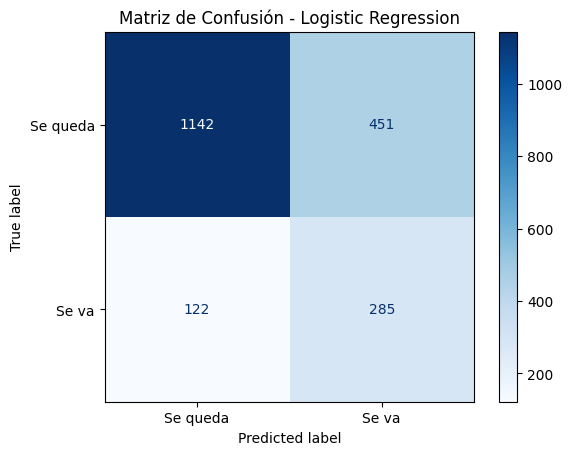

================ Random Forest ================
              precision    recall  f1-score   support

Se queda (0)       0.87      0.97      0.92      1593
   Se va (1)       0.77      0.43      0.55       407

    accuracy                           0.86      2000
   macro avg       0.82      0.70      0.73      2000
weighted avg       0.85      0.86      0.84      2000



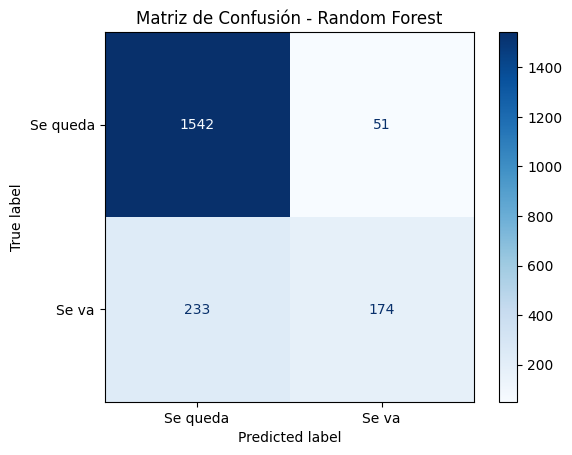

In [26]:
# 6. Entrenamiento, evaluación y matrices de confusión
results = []
for name, clf in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", clf)
    ])

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    # Cálculo de métricas
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Modelo": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "AUC-ROC": round(auc, 4)
    })

    print(f"================ {name} ================")
    print(classification_report(y_test, y_pred, target_names=["Se queda (0)", "Se va (1)"]))

    # Visualización de la Matriz de Confusión
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Se queda", "Se va"])
    disp.plot(cmap="Blues")
    plt.title(f"Matriz de Confusión - {name}")
    plt.show()


In [27]:
# 7. Tabla resumen comparativa
df_metrics = pd.DataFrame(results)
print("\n--- Resumen de Métricas ---")
print(df_metrics.to_string(index=False))


--- Resumen de Métricas ---
             Modelo  Accuracy  Precision  Recall  F1-Score  AUC-ROC
Logistic Regression    0.7135     0.3872  0.7002    0.4987   0.7772
      Random Forest    0.8580     0.7733  0.4275    0.5506   0.8488


## Conclusión e Interpretación de Negocio (Churn Bancario)

### ¿Cuál es la métrica más importante para este problema?
En un problema de **abandono de clientes (*Churn*) bancario**, la métrica prioritaria es el **Recall (Sensibilidad)** sobre la clase positiva (`Exited = 1`, cliente que abandona), evaluada en conjunto con el **F1-Score** para mantener un equilibrio razonable con la precisión.

### Impacto de los errores: Falsos Negativos vs. Falsos Positivos
* **Falso Negativo (FN — predice `0`, pero el cliente abandona `1`):** El modelo indica que el cliente permanecerá en el banco, por lo que no se activa ninguna acción preventiva, pero el cliente finalmente cierra su cuenta o deja de operar. Este error es **altamente costoso** para el negocio porque implica la pérdida de ingresos recurrentes y margen financiero (saldos, comisiones, productos asociados), además de obligar al banco a invertir luego en captar un cliente nuevo (cuyo costo de adquisición suele ser mucho mayor que el de retención).
* **Falso Positivo (FP — predice `1`, pero el cliente se queda `0`):** El modelo marca a un cliente como en riesgo de fuga cuando en realidad no pensaba irse. Esto puede derivar en ofrecerle una bonificación, tasa preferencial o contacto comercial de retención innecesario. Aunque representa un gasto operativo o promocional, **su costo es considerablemente menor** que perder definitivamente a un cliente activo.

### Síntesis de los modelos evaluados (Set de prueba 80/20)
| Modelo | Accuracy | Precision | Recall | F1-Score | AUC-ROC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Logistic Regression** | 0.7135 | 0.3872 | 0.7002 | 0.4987 | 0.7772 |
| **Random Forest** | 0.8580 | 0.7733 | 0.4275 | 0.5506 | 0.8488 |

* **Logistic Regression** logra un **Recall mucho mayor (0.7002 vs. 0.4275)**, capturando alrededor del 70% de los clientes que realmente abandonan el banco. A cambio, presenta menor **Precision (0.3872)**, lo que genera más alertas de retención sobre clientes que no iban a irse (falsos positivos).

* **Random Forest** obtiene mejores valores globales de **Accuracy (0.8580)**, **Precision (0.7733)**, **F1-Score (0.5506)** y **AUC-ROC (0.8488)**, evitando muchas acciones de retención innecesarias, pero **deja escapar a más de la mitad de los clientes que abandonan** (bajo Recall de 0.4275), lo que implica un mayor costo por **Falsos Negativos** si el objetivo principal del banco es frenar la fuga.

* **Decisión de negocio:** Si la prioridad del banco es **maximizar la retención y minimizar la pérdida de clientes** (y el costo de una acción preventiva es bajo), **Logistic Regression** es más útil como primera línea de detección por su mayor **Recall**; en cambio, si las campañas de retención tienen un costo elevado o capacidad operativa limitada, **Random Forest** (o el ajuste del umbral de probabilidad del modelo) permite focalizar mejor los recursos.

